# 01 · Bronce, plata y oro · IAQ (Frank)
Sesión 3 · AireIQ · Equipo Novoa

**Flujo:** `data/raw/mediciones_aire.csv` → **bronce** (dato tal cual, Parquet por fecha) → **plata** (limpio, 1 minuto) → **oro** (indicadores del brief).

Todo se guarda en `data/` . Las fechas y horas se calculan en hora de Lima.

In [1]:
from pathlib import Path
from pyspark.sql import SparkSession, functions as F, types as T

# Raíz del repositorio: sube hasta encontrar la carpeta data/
ROOT = Path.cwd().resolve()
while not (ROOT / "data").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "data").is_dir(), "No encuentro la carpeta data/ del repositorio"

RAW    = ROOT / "data" / "raw" / "mediciones_aire.csv"
BRONZE = ROOT / "data" / "bronze" / "mediciones_aire"
SILVER = ROOT / "data" / "silver" / "mediciones_1min"
GOLD   = ROOT / "data" / "gold"

# Parámetros del brief
REF_INICIO, REF_FIN = "2026-10-29", "2026-11-01"   # periodo de referencia del umbral
print("Raíz:", ROOT, "| CSV existe:", RAW.exists())

spark = (SparkSession.builder.appName("aireiq-frank-01")
         .master("local[*]")
         .config("spark.sql.session.timeZone", "America/Lima")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
spark.version

Raíz: /home/jovyan/work | CSV existe: True


'3.5.3'

## 1 · Bronce: leer el CSV con esquema explícito y guardar tal cual

In [2]:
schema = T.StructType([
    T.StructField("id", T.LongType()),
    T.StructField("created_at", T.StringType()),     # se convierte a timestamp abajo
    T.StructField("dispositivo", T.StringType()),
    T.StructField("temperatura_c", T.DoubleType()),
    T.StructField("humedad_pct", T.DoubleType()),
    T.StructField("presion_hpa", T.DoubleType()),
    T.StructField("gas_ohms", T.DoubleType()),
    T.StructField("altura_m", T.DoubleType()),
    T.StructField("iaq_estimado", T.DoubleType()),
    T.StructField("eco2_estimado_ppm", T.DoubleType()),
    T.StructField("voc_indice_estimado", T.DoubleType()),
    T.StructField("calidad_aire", T.StringType()),
])

crudo = (spark.read.option("header", True).schema(schema).csv(str(RAW)))
n_crudo = crudo.count()

bronce = (crudo
          .withColumn("ts", F.to_timestamp("created_at"))
          .withColumn("fecha", F.to_date("ts"))
          .withColumn("_ingesta", F.current_timestamp()))

(bronce.write.mode("overwrite").partitionBy("fecha").parquet(str(BRONZE)))
n_bronce = spark.read.parquet(str(BRONZE)).count()
print(f"CSV: {n_crudo:,} filas | Bronce (Parquet): {n_bronce:,} filas | ida y vuelta OK: {n_crudo == n_bronce}")
print("Marcas de tiempo que no se pudieron leer:", bronce.filter(F.col("ts").isNull()).count())

CSV: 8,459 filas | Bronce (Parquet): 8,459 filas | ida y vuelta OK: True
Marcas de tiempo que no se pudieron leer: 0


## 2 · Plata: limpiar y llevar a 1 minuto
Reglas (brief, sección 6):
1. Excluir `gas_ohms = 0` o nulo (fallo del sensor).
2. Quitar duplicados exactos de `(dispositivo, ts)`.
3. Mantener solo valores dentro del rango físico del BME680.
4. Promediar por minuto.

In [3]:
b = spark.read.parquet(str(BRONZE))

reglas = [
    ("gas_ohms = 0 o nulo",   (F.col("gas_ohms").isNull()) | (F.col("gas_ohms") <= 0)),
    ("fuera de rango físico",
        (F.col("temperatura_c").between(-40, 85) == False) |
        (F.col("humedad_pct").between(0, 100) == False) |
        (F.col("presion_hpa").between(300, 1100) == False) |
        (F.col("iaq_estimado").between(0, 500) == False)),
]

resumen = [("filas en bronce", b.count())]
actual = b.dropDuplicates(["dispositivo", "ts"])
resumen.append(("duplicados eliminados", b.count() - actual.count()))
for nombre, cond in reglas:
    malas = actual.filter(cond).count()
    resumen.append((nombre, malas))
    actual = actual.filter(~cond)
resumen.append(("filas válidas", actual.count()))
spark.createDataFrame(resumen, ["regla", "filas"]).show(truncate=False)

+---------------------+-----+
|regla                |filas|
+---------------------+-----+
|filas en bronce      |8459 |
|duplicados eliminados|0    |
|gas_ohms = 0 o nulo  |777  |
|fuera de rango físico|0    |
|filas válidas        |7682 |
+---------------------+-----+



In [4]:
plata = (actual
    .groupBy(F.window("ts", "1 minute").alias("w"))
    .agg(F.avg("iaq_estimado").alias("iaq"),
         F.avg("temperatura_c").alias("temperatura_c"),
         F.avg("humedad_pct").alias("humedad_pct"),
         F.avg("presion_hpa").alias("presion_hpa"),
         F.avg("gas_ohms").alias("gas_ohms"),
         F.count("*").alias("n_lecturas"))
    .select(F.col("w.start").alias("minuto"), "iaq", "temperatura_c",
            "humedad_pct", "presion_hpa", "gas_ohms", "n_lecturas")
    .withColumn("fecha", F.to_date("minuto"))
    .withColumn("hora", F.hour("minuto")))

(plata.write.mode("overwrite").partitionBy("fecha").parquet(str(SILVER)))
s = spark.read.parquet(str(SILVER))
print(f"Plata: {s.count():,} minutos con datos | del {s.agg(F.min('minuto')).first()[0]} al {s.agg(F.max('minuto')).first()[0]}")
s.orderBy("minuto").show(5, truncate=False)

Plata: 2,863 minutos con datos | del 2026-10-22 04:52:00 al 2026-11-06 19:40:00
+-------------------+-------+-------------+-----------+-----------+--------+----------+----+----------+
|minuto             |iaq    |temperatura_c|humedad_pct|presion_hpa|gas_ohms|n_lecturas|hora|fecha     |
+-------------------+-------+-------------+-----------+-----------+--------+----------+----+----------+
|2026-10-21 23:52:00|7.83671|18.7746      |37.3878    |647.35     |398474.0|1         |23  |2026-10-21|
|2026-10-21 23:53:00|7.9897 |18.7791      |37.3368    |647.34     |421737.0|1         |23  |2026-10-21|
|2026-10-21 23:54:00|8.24709|18.8374      |37.251     |647.33     |425476.0|1         |23  |2026-10-21|
|2026-10-21 23:55:00|8.3926 |18.8675      |37.2025    |647.33     |441992.0|1         |23  |2026-10-21|
|2026-10-21 23:56:00|8.54946|18.9174      |37.1502    |647.32     |438244.0|1         |23  |2026-10-21|
+-------------------+-------+-------------+-----------+-----------+--------+----------+-

## 3 · Oro: umbral y minutos fuera de rango
Umbral = percentil 5 y 95 del IAQ en el periodo de referencia. Un IAQ mayor es peor, así que el riesgo es sobre el p95.

In [5]:
s = spark.read.parquet(str(SILVER))

ref = s.filter(F.col("fecha").between(REF_INICIO, REF_FIN))
p5, p95 = ref.approxQuantile("iaq", [0.05, 0.95], 0.001)
print(f"Referencia {REF_INICIO} a {REF_FIN}: {ref.count():,} minutos | p5 = {p5:.2f} | p95 = {p95:.2f}")

fuera = s.withColumn("fuera_p95", (F.col("iaq") > p95).cast("int"))

por_dia = (fuera.groupBy("fecha")
           .agg(F.count("*").alias("minutos"),
                F.sum("fuera_p95").alias("min_fuera_p95"))
           .withColumn("pct_fuera_p95", F.round(100 * F.col("min_fuera_p95") / F.col("minutos"), 1))
           .orderBy("fecha"))

por_hora = (fuera.groupBy("hora")
            .agg(F.count("*").alias("minutos"),
                 F.sum("fuera_p95").alias("min_fuera_p95"),
                 F.round(F.avg("iaq"), 2).alias("iaq_prom"),
                 F.round(F.min("iaq"), 2).alias("iaq_min"),
                 F.round(F.max("iaq"), 2).alias("iaq_max"))
            .withColumn("pct_fuera_p95", F.round(100 * F.col("min_fuera_p95") / F.col("minutos"), 1))
            .orderBy("hora"))

por_dia.write.mode("overwrite").parquet(str(GOLD / "iaq_fuera_p95_por_dia"))
por_hora.write.mode("overwrite").parquet(str(GOLD / "iaq_fuera_p95_por_hora"))
spark.createDataFrame([(REF_INICIO, REF_FIN, float(p5), float(p95))],
                      ["ref_inicio", "ref_fin", "p5", "p95"]
                     ).write.mode("overwrite").parquet(str(GOLD / "umbral_iaq"))

por_dia.show(40, truncate=False)

Referencia 2026-10-29 a 2026-11-01: 1,277 minutos | p5 = 5.77 | p95 = 32.26
+----------+-------+-------------+-------------+
|fecha     |minutos|min_fuera_p95|pct_fuera_p95|
+----------+-------+-------------+-------------+
|2026-10-21|5      |0            |0.0          |
|2026-10-22|768    |1            |0.1          |
|2026-10-23|10     |0            |0.0          |
|2026-10-28|195    |0            |0.0          |
|2026-10-29|624    |2            |0.3          |
|2026-10-30|233    |21           |9.0          |
|2026-10-31|46     |9            |19.6         |
|2026-11-01|374    |32           |8.6          |
|2026-11-05|102    |0            |0.0          |
|2026-11-06|506    |145          |28.7         |
+----------+-------+-------------+-------------+



In [6]:
por_hora.show(24, truncate=False)

+----+-------+-------------+--------+-------+-------+-------------+
|hora|minutos|min_fuera_p95|iaq_prom|iaq_min|iaq_max|pct_fuera_p95|
+----+-------+-------------+--------+-------+-------+-------------+
|0   |183    |0            |7.2     |0.04   |17.07  |0.0          |
|1   |132    |0            |4.89    |0.05   |15.26  |0.0          |
|2   |119    |0            |5.18    |0.18   |8.42   |0.0          |
|3   |135    |0            |9.37    |0.05   |32.2   |0.0          |
|4   |84     |0            |5.22    |0.07   |13.15  |0.0          |
|5   |101    |0            |7.56    |0.13   |23.38  |0.0          |
|6   |76     |0            |3.43    |0.11   |12.21  |0.0          |
|7   |58     |0            |2.22    |0.03   |10.58  |0.0          |
|8   |91     |11           |9.41    |0.17   |43.48  |12.1         |
|9   |275    |77           |22.07   |0.04   |48.15  |28.0         |
|10  |235    |31           |20.12   |0.42   |48.72  |13.2         |
|11  |147    |3            |17.77   |2.29   |34.

## 4 · Gráficos rápidos

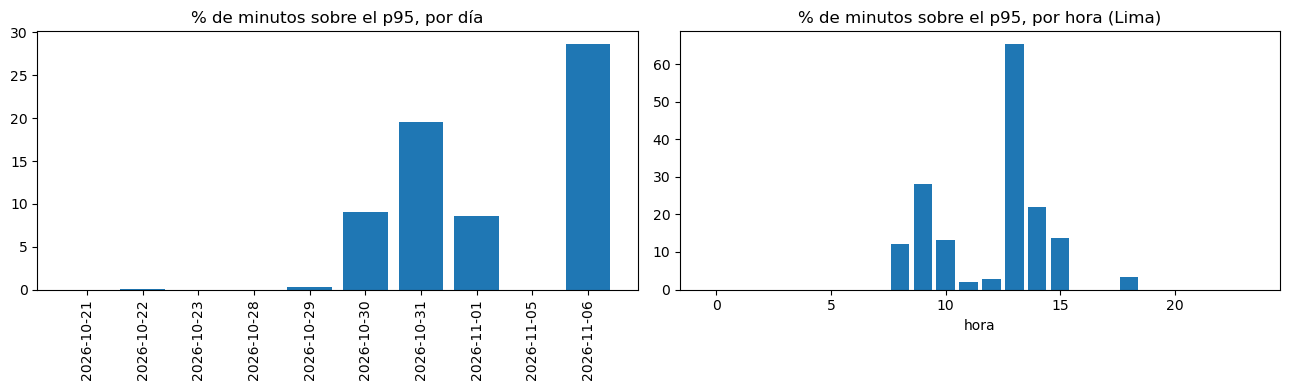

In [7]:
import matplotlib.pyplot as plt
d = por_dia.toPandas(); h = por_hora.toPandas()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(d["fecha"].astype(str), d["pct_fuera_p95"]); ax[0].set_title("% de minutos sobre el p95, por día")
ax[0].tick_params(axis="x", rotation=90)
ax[1].bar(h["hora"], h["pct_fuera_p95"]); ax[1].set_title("% de minutos sobre el p95, por hora (Lima)")
ax[1].set_xlabel("hora"); plt.tight_layout(); plt.show()

## 5 · Verificación

In [8]:
# 1) El Parquet particionado se poda por fecha (debe aparecer PartitionFilters)
spark.read.parquet(str(SILVER)).filter(F.col("fecha") == "2026-11-05").explain(True)

== Parsed Logical Plan ==
'Filter ('fecha = 2026-11-05)
+- Relation [minuto#1157,iaq#1158,temperatura_c#1159,humedad_pct#1160,presion_hpa#1161,gas_ohms#1162,n_lecturas#1163L,hora#1164,fecha#1165] parquet

== Analyzed Logical Plan ==
minuto: timestamp, iaq: double, temperatura_c: double, humedad_pct: double, presion_hpa: double, gas_ohms: double, n_lecturas: bigint, hora: int, fecha: date
Filter (fecha#1165 = cast(2026-11-05 as date))
+- Relation [minuto#1157,iaq#1158,temperatura_c#1159,humedad_pct#1160,presion_hpa#1161,gas_ohms#1162,n_lecturas#1163L,hora#1164,fecha#1165] parquet

== Optimized Logical Plan ==
Filter (isnotnull(fecha#1165) AND (fecha#1165 = 2026-11-05))
+- Relation [minuto#1157,iaq#1158,temperatura_c#1159,humedad_pct#1160,presion_hpa#1161,gas_ohms#1162,n_lecturas#1163L,hora#1164,fecha#1165] parquet

== Physical Plan ==
*(1) ColumnarToRow
+- FileScan parquet [minuto#1157,iaq#1158,temperatura_c#1159,humedad_pct#1160,presion_hpa#1161,gas_ohms#1162,n_lecturas#1163L,hora#1164

In [9]:
# 2) Conteos entre capas
print("CSV      :", n_crudo)
print("Bronce   :", spark.read.parquet(str(BRONZE)).count())
print("Plata    :", spark.read.parquet(str(SILVER)).count(), "(minutos con datos válidos)")
print("Oro días :", spark.read.parquet(str(GOLD / "iaq_fuera_p95_por_dia")).count())

CSV      : 8459
Bronce   : 8459
Plata    : 2863 (minutos con datos válidos)
Oro días : 10


**Siguiente (S4):** tabla de entrenamiento con rezagos del IAQ y la etiqueta *supera el p95 en la próxima hora*; modelos y guardado del ganador en `models/`.